# ECG dataset → Cayetino R4 DAC files

This notebook selects one held-out ECG window per class from `ecg_dataset.npz` and writes CSV files accepted by the [Cayetino R4 signal player](https://github.com/MSMRo/CAYETINO_R4). The CSV contains the player metadata and `index,dac_value,voltage_v` columns. Upload one of the generated `.CSV` files in Cayetino and play it at its declared **500 Hz**.

The classifier was trained on 187 samples at 250 Hz and z-score-normalized each window. Therefore, each source sample is held for two DAC ticks (374 samples total, same duration); the Pico sketch samples at 500 Hz and keeps every other ADC sample to reconstruct the model's 187-point, 250 Hz window. The level is mapped into a safe 0.35–2.95 V range; verify the Cayetino A0 output voltage before connecting it to a Pico ADC input, and connect both boards' grounds.

> These are synthetic training examples for a software/hardware demonstration, not clinically validated ECG signals or a medical diagnostic device.

In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt

DATASET_NAME = "ecg_dataset.npz"
dataset_candidates = [Path.cwd() / DATASET_NAME]
dataset_candidates.extend(
    parent / "01_ecg_arrhythmia_ptq_tensorflow" / "python" / DATASET_NAME
    for parent in (Path.cwd(), *Path.cwd().parents)
)
DATASET_PATH = next((path for path in dataset_candidates if path.is_file()), None)
if DATASET_PATH is None:
    raise FileNotFoundError(
        "Could not find ecg_dataset.npz. Run this notebook in the project or ECG python folder."
    )

OUTPUT_DIR = DATASET_PATH.parent / "cayetino_upload"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_SAMPLE_RATE_HZ = 250
PLAYER_SAMPLE_RATE_HZ = 500
MODEL_WINDOW_SAMPLES = 187
DAC_BITS = 12
DAC_MAX_CODE = (1 << DAC_BITS) - 1
DAC_FULL_SCALE_V = 3.3
SAFE_MIN_V = 0.35
SAFE_MAX_V = 2.95
CLASS_NAMES = {0: "ECG_NORM_500", 1: "ECG_TACH_500", 2: "ECG_BRAD_500"}

if PLAYER_SAMPLE_RATE_HZ % MODEL_SAMPLE_RATE_HZ != 0:
    raise ValueError("Player rate must be an integer multiple of the model sample rate.")
REPEAT_FACTOR = PLAYER_SAMPLE_RATE_HZ // MODEL_SAMPLE_RATE_HZ

dataset = np.load(DATASET_PATH)
X_test = dataset["X_test"].astype(np.float32)
y_test = dataset["y_test"].astype(np.int64)
if X_test.ndim != 3 or X_test.shape[1:] != (MODEL_WINDOW_SAMPLES, 1):
    raise ValueError(f"Expected X_test shape (N, 187, 1); found {X_test.shape}.")
print(f"Loaded {len(X_test)} test windows from {DATASET_PATH}")
print(f"Output directory: {OUTPUT_DIR}")

Loaded 300 test windows from d:\DOCUMENTOS\PROJECTS\PICO2_TINYML\01_ecg_arrhythmia_ptq_tensorflow\python\ecg_dataset.npz
Output directory: d:\DOCUMENTOS\PROJECTS\PICO2_TINYML\01_ecg_arrhythmia_ptq_tensorflow\python\cayetino_upload


## Choose one test signal for each trained class

The original training generator applies `(window - mean) / std`. The Cayetino CSV cannot carry negative values, so this exporter applies a linear voltage mapping to each selected window. The Pico removes that offset and gain with the same per-window normalization before INT8 quantization.

In [2]:
def to_cayetino_codes(window: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Map one normalized dataset window to safe voltage and 12-bit DAC codes."""
    values = np.asarray(window, dtype=np.float32).reshape(-1)
    if values.size != MODEL_WINDOW_SAMPLES or not np.all(np.isfinite(values)):
        raise ValueError("Window must contain 187 finite samples.")
    value_min = float(values.min())
    value_max = float(values.max())
    if value_max - value_min <= 1e-8:
        raise ValueError("Cannot export a constant ECG window.")

    voltage = SAFE_MIN_V + (values - value_min) * (
        (SAFE_MAX_V - SAFE_MIN_V) / (value_max - value_min)
    )
    codes = np.rint(voltage / DAC_FULL_SCALE_V * DAC_MAX_CODE)
    codes = np.clip(codes, 0, DAC_MAX_CODE).astype(np.uint16)
    actual_voltage = codes.astype(np.float32) / DAC_MAX_CODE * DAC_FULL_SCALE_V
    return codes, actual_voltage


def write_cayetino_csv(name: str, codes: np.ndarray, voltage: np.ndarray) -> Path:
    """Write the Cayetino R4 CSV metadata and sample-column format."""
    path = OUTPUT_DIR / f"{name}.CSV"
    with path.open("w", newline="", encoding="utf-8") as file:
        file.write(f"# Name: {name}\n")
        file.write(f"# SamplingRate: {PLAYER_SAMPLE_RATE_HZ}\n")
        file.write(f"# Samples: {len(codes)}\n")
        file.write(f"# Duration_s: {len(codes) / PLAYER_SAMPLE_RATE_HZ:.3f}\n")
        file.write(f"# BitResolution: {DAC_BITS}\n")
        writer = csv.writer(file, lineterminator="\n")
        writer.writerow(("index", "dac_value", "voltage_v"))
        for index, (code, volts) in enumerate(zip(codes, voltage, strict=True)):
            writer.writerow((index, int(code), f"{float(volts):.4f}"))
    return path


exported = {}
for class_id, name in CLASS_NAMES.items():
    matching = np.flatnonzero(y_test == class_id)
    if matching.size == 0:
        raise ValueError(f"No test samples found for class {class_id} ({name}).")
    source_index = int(matching[0])
    codes_250, voltage_250 = to_cayetino_codes(X_test[source_index, :, 0])

    # Hold each source sample for two ticks: playback stays 500 Hz without speeding up the ECG.
    codes_500 = np.repeat(codes_250, REPEAT_FACTOR)
    voltage_500 = np.repeat(voltage_250, REPEAT_FACTOR)
    output_path = write_cayetino_csv(name, codes_500, voltage_500)
    exported[name] = {
        "path": output_path,
        "class_id": class_id,
        "source_index": source_index,
        "codes": codes_500,
        "voltage": voltage_500,
    }
    print(
        f"{output_path.name}: class={class_id}, samples={len(codes_500)}, "
        f"duration={len(codes_500) / PLAYER_SAMPLE_RATE_HZ:.3f}s, "
        f"voltage={voltage_500.min():.3f}..{voltage_500.max():.3f} V"
    )

ECG_NORM_500.CSV: class=0, samples=374, duration=0.748s, voltage=0.350..2.950 V
ECG_TACH_500.CSV: class=1, samples=374, duration=0.748s, voltage=0.350..2.950 V
ECG_BRAD_500.CSV: class=2, samples=374, duration=0.748s, voltage=0.350..2.950 V


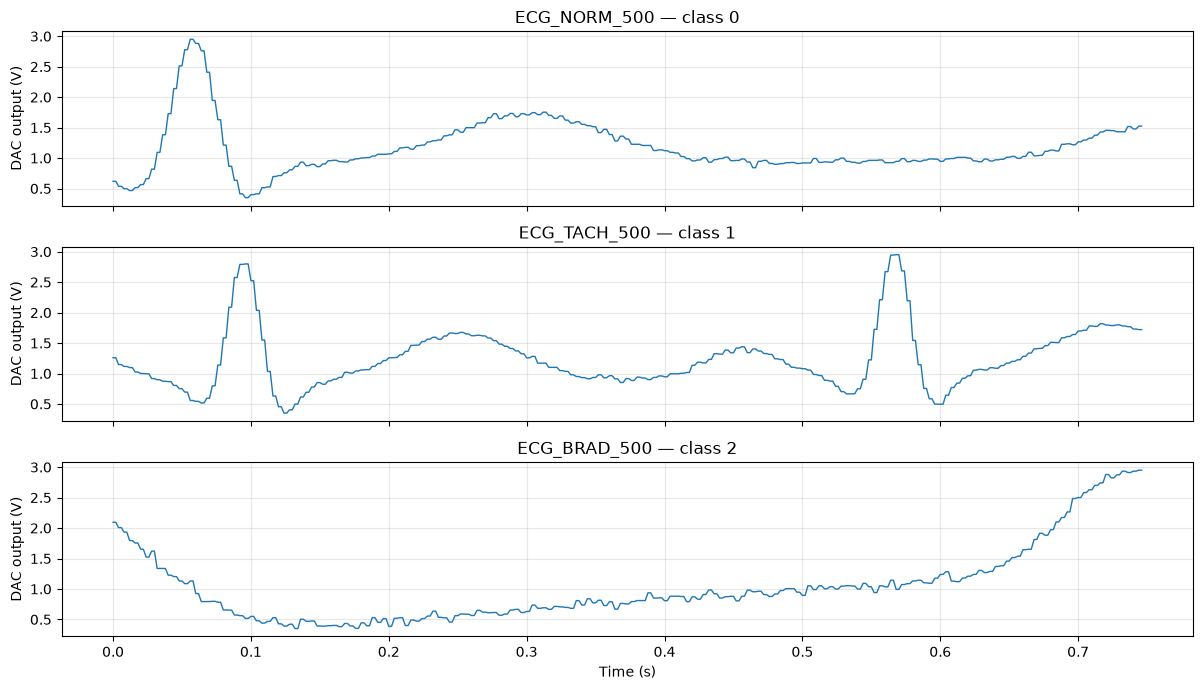

In [3]:
fig, axes = plt.subplots(len(exported), 1, figsize=(12, 7), sharex=True)
time_s = np.arange(MODEL_WINDOW_SAMPLES * REPEAT_FACTOR) / PLAYER_SAMPLE_RATE_HZ
for axis, (name, result) in zip(axes, exported.items(), strict=True):
    axis.plot(time_s, result["voltage"], linewidth=1)
    axis.set_title(f"{name} — class {result['class_id']}")
    axis.set_ylabel("DAC output (V)")
    axis.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()

In [4]:
# Re-read each CSV and check the same fields the Cayetino parser consumes.
for name, result in exported.items():
    lines = result["path"].read_text(encoding="utf-8").splitlines()
    assert f"# SamplingRate: {PLAYER_SAMPLE_RATE_HZ}" in lines
    assert f"# Samples: {MODEL_WINDOW_SAMPLES * REPEAT_FACTOR}" in lines
    assert lines[5] == "index,dac_value,voltage_v"
    rows = list(csv.reader(lines[6:]))
    assert len(rows) == MODEL_WINDOW_SAMPLES * REPEAT_FACTOR
    parsed_codes = np.array([int(row[1]) for row in rows])
    assert np.array_equal(parsed_codes, result["codes"])
    assert np.all((parsed_codes >= 0) & (parsed_codes <= DAC_MAX_CODE))
print("All three Cayetino CSV files passed metadata, row-count, and 12-bit range checks.")

All three Cayetino CSV files passed metadata, row-count, and 12-bit range checks.


## Hardware sequence

1. Run this notebook; it writes `ECG_NORM_500.CSV`, `ECG_TACH_500.CSV`, and `ECG_BRAD_500.CSV` under `python/cayetino_upload/`.
2. Upload one CSV to Cayetino R4 and play it at **500 Hz** (the rate is also embedded in the file).
3. Connect Cayetino **A0 → Pico GP26 / ADC0** and **GND → GND**. The exporter maps output to 0.35–2.95 V; still measure A0 first. Never apply more than 3.3 V to a Pico ADC pin.
4. Flash `arduino/ecg_adc_inference_pico/ecg_adc_inference_pico.ino` to the Pico. The sketch acquires at 500 samples/s, decimates by two, z-score-normalizes 187 samples, and runs the existing INT8 ECG model.

This verifies the end-to-end software path with generated signals. The classifier was trained on synthetic data and may not generalize to real ECG sensors or clinical signals.